# Physiological Synchrony: Time Series & Robustness Plots
This notebook generates the visualisations for my dissertation:
- **Plot 1:** Raw heart rate time series of both participants in a session.
- **Plot 2:** Windowed cross-correlation over time (30 s sliding window).
- **Plot 3:** Per-pair synchrony comparison across conditions (Haptics ON vs. Haptics OFF).
- **Plot 4 & Table:** Window size robustness analysis (15s, 30s, 45s, 60s, 90s).

In [145]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

## 1. Signal Processing Helper Functions
Defines the core mathematical transformations:
1. first_difference(): Prewhitens the series by calculating second-by-second changes ($X_t - X_{t-1}$).
2. windowed_correlation(): Slides a moving window across both series to compute Pearson correlation over time.
3. mean_synchrony(): Computes the single session-level synchrony score (mean Pearson's $r$).

In [150]:
from scipy.stats import pearsonr
def first_difference(heart_rate_series):
    # Turn heart rate series into the change from one second to the next.

    heart_rate_array = np.asarray(heart_rate_series, dtype=float)
    return np.diff(heart_rate_array)


def windowed_correlation(heart_rate_changes_a, heart_rate_changes_b, window_size_seconds=30):
  
    # ensure we only loop over seconds where both participants have data
    total_seconds = min(len(heart_rate_changes_a), len(heart_rate_changes_b))
    
    window_centres = []
    window_correlations = []
    
    # slide the window one second at a time across the entire session
    total_possible_windows = total_seconds - window_size_seconds + 1
    
    for window_start in range(total_possible_windows):
        window_end = window_start + window_size_seconds
        
        # extract the 30-second slice of data for both participants
        slice_participant_a = heart_rate_changes_a[window_start:window_end]
        slice_participant_b = heart_rate_changes_b[window_start:window_end]
        
        # Calculate the Pearson correlation for this specific 30-second slice
        pearson_r, p_value = pearsonr(slice_participant_a, slice_participant_b)
        window_correlations.append(pearson_r)
        
        # Record the center point (in seconds) to plot on the X-axis
        center_second = window_start + (window_size_seconds / 2)
        window_centres.append(center_second)
        
    return np.array(window_centres), np.array(window_correlations)




def mean_synchrony(heart_rate_changes_a, heart_rate_changes_b, window_size_seconds=30):
    # The single synchrony score: the average correlation across all windows
    window_centres, window_correlations = windowed_correlation(
        heart_rate_changes_a, 
        heart_rate_changes_b, 
        window_size_seconds
    )
    return np.nanmean(window_correlations)

## 2. Session Data Extraction
Loads resampled_data.csv and provides get_session(pair_id, phase) to extract and align timestamped heart rate series for any chosen dyad and experimental phase.

In [ ]:
resampled_data = pd.read_csv("resampled_data.csv")

def get_session(pair_id, phase):

    one_pair = resampled_data[(resampled_data["pair_id"] == pair_id) & (resampled_data["phase"] == phase)]

    alpha = one_pair[one_pair["participant"] == "Alpha"].sort_values("time_s")
    bravo = one_pair[one_pair["participant"] == "Bravo"].sort_values("time_s")

    shared_seconds = sorted(set(alpha["time_s"]) & set(bravo["time_s"]))
    alpha = alpha[alpha["time_s"].isin(shared_seconds)].sort_values("time_s")
    bravo = bravo[bravo["time_s"].isin(shared_seconds)].sort_values("time_s")

    time_seconds = alpha["time_s"].to_numpy()
    heart_rate_a = alpha["bpm"].to_numpy(float)
    heart_rate_b = bravo["bpm"].to_numpy(float)
    return time_seconds, heart_rate_a, heart_rate_b

print("Pairs :", sorted(resampled_data["pair_id"].unique()))
print("Phases:", list(resampled_data["phase"].unique()))

Pairs : ['pair_02', 'pair_03', 'pair_04', 'pair_05', 'pair_06', 'pair_07', 'pair_08', 'pilot_01']
Phases: ['baseline', 'hapticsON_settle', 'hapticsON_task', 'transition', 'hapticsOFF_settle', 'hapticsOFF_task']


## 3. Session Selection for Time Series Visualisation
Select a specific pair and phase to inspect individual cardiac dynamics.


In [152]:
pair_id = "pair_06"
phase = "baseline"

time_seconds, heart_rate_a, heart_rate_b = get_session(pair_id, phase)

# turn each heart rate into second-by-second change, ready for the correlations
heart_rate_change_a = first_difference(heart_rate_a)
heart_rate_change_b = first_difference(heart_rate_b)

print(f"{pair_id} / {phase}: {len(time_seconds)} seconds of shared data")

pair_06 / baseline: 247 seconds of shared data


### Plot 1: Heart Rate Time Series
Plots Participant Alpha and Participant Bravo on the same axes to inspect simultaneous heart rate fluctuations.

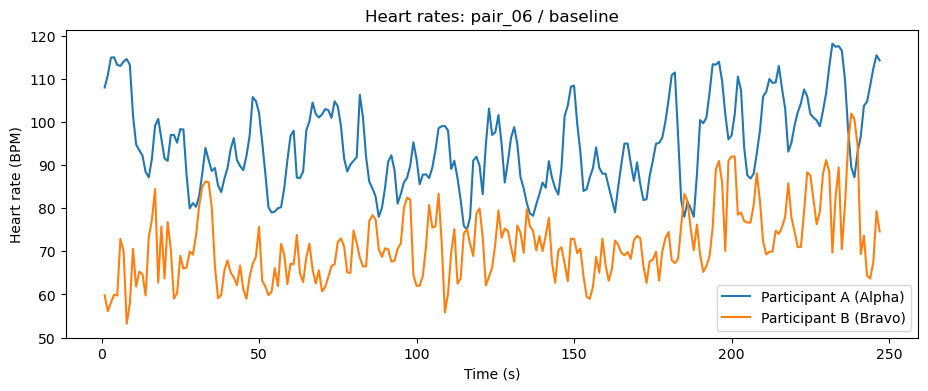

In [ ]:
plt.figure(figsize=(11, 4))
plt.plot(time_seconds, heart_rate_a, label="Participant A (Alpha)")
plt.plot(time_seconds, heart_rate_b, label="Participant B (Bravo)")
plt.xlabel("Time (seconds)")
plt.ylabel("Heart rate (BPM)")
plt.title(f"Heart rates: {pair_id} / {phase}")
plt.legend()
plt.savefig("fig_name.png", dpi=200, bbox_inches="tight")
plt.show()

### Plot 2: Windowed Cross-Correlation Over Time
Visualises how physiological synchrony fluctuates across the session using a 30-second sliding window advancing in 1-second steps.

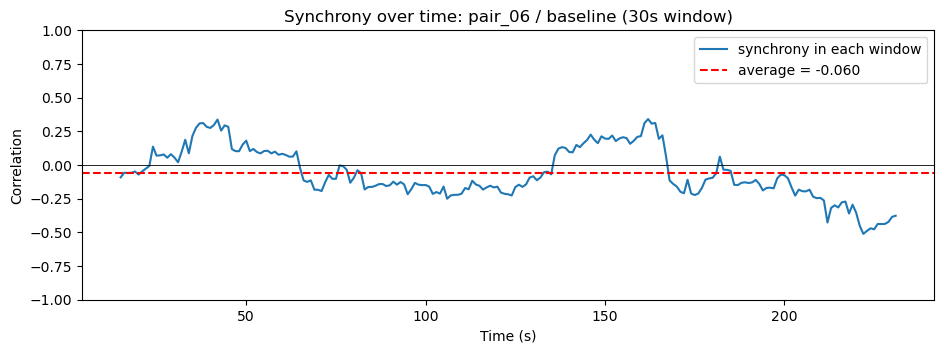

In [156]:
window_size = 30
window_centres, window_correlations = windowed_correlation(
    heart_rate_change_a, heart_rate_change_b, window_size)

mean_average_correlation = np.nanmean(window_correlations)

plt.figure(figsize=(11, 3.5))
plt.plot(window_centres, correlations, label="synchrony in each window")
plt.axhline(0, color="black", linewidth=0.6)
plt.axhline(mean_average_correlation, color="red", linestyle="--",
            label=f"average = {mean_average_correlation:.3f}")
plt.ylim(-1, 1)
plt.xlabel("Time (s)")
plt.ylabel("Correlation")
plt.title(f"Synchrony over time: {pair_id} / {phase} ({window_size}s window)")
plt.legend()
plt.savefig("fig_name.png", dpi=200, bbox_inches="tight")
plt.show()


### Plot 3: Per-Pair Synchrony Comparison (Bar Plot)
Compares mean synchrony between **Haptics OFF** and **Haptics ON** for every individual pair, alongside the overall cohort average.

In [ ]:
condition_names = ["hapticsOFF_task", "hapticsON_task"] #"baseline",
all_pair_ids = sorted(resampled_data["pair_id"].unique())

synchrony_summary_table = pd.DataFrame(index=all_pair_ids, columns=condition_names, dtype=float)

for pair_id in all_pair_ids:
    for condition in condition_names:
        time_seconds, heart_rate_a, heart_rate_b = get_session(pair_id, condition)

        heart_rate_change_a = first_difference(heart_rate_a)
        heart_rate_change_b = first_difference(heart_rate_b)

        synchrony_summary_table.loc[pair_id, condition] = mean_synchrony(heart_rate_change_a, heart_rate_change_b)

print("Synchrony Summary Table (Pearson r) (30s):")
display(synchrony_summary_table.round(3))

Synchrony Summary Table (Pearson r) (30s):


,hapticsOFF_task,hapticsON_task
pair_02,0.041,-0.149
pair_03,0.089,-0.096
pair_04,-0.073,0.055
pair_05,-0.002,-0.070
pair_06,0.006,-0.050
pair_07,0.030,-0.006
pair_08,-0.014,0.041
pilot_01,-0.089,-0.080


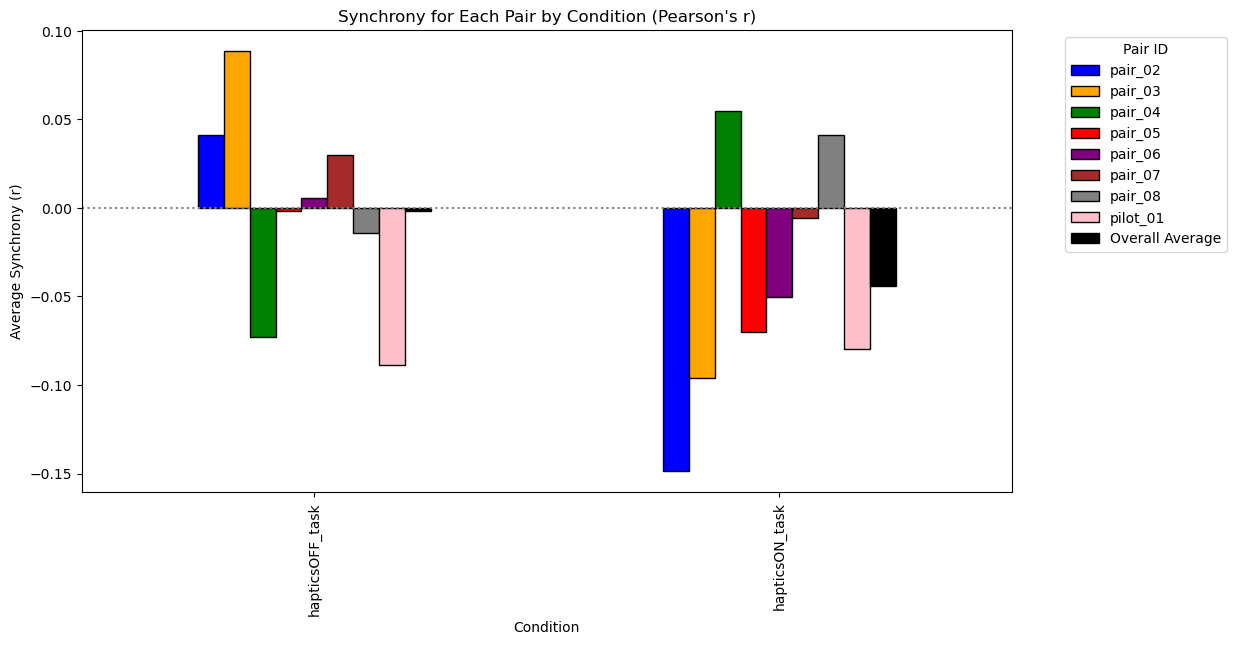

In [164]:

plot_data = synchrony_table.copy()

# calculate average for each condition for comparison
plot_data.loc['Overall Average'] = plot_data.mean()

# colours
colour_list =[]

standard_colours = ['blue', 'orange', 'green', 'red', 'purple', 'brown', 'grey','pink', 'yellow']
# assign colour
current_colour_index = 0
for pair in pair_ids:
    chosen_colour = standard_colours[current_colour_index]
    colour_list.append(chosen_colour)

    # move to next colour
    current_colour_index = current_colour_index +1
    # if run out of colours
    if current_colour_index == len(standard_colours):
        current_colour_index = 0

colour_list.append('black')

# Plot the side-by-side bars 
ax = plot_data.T.plot(kind="bar", figsize=(12, 6), color=colour_list, edgecolor='black')

plt.title("Synchrony for Each Pair by Condition (Pearson's r)")
plt.ylabel("Average Synchrony (r)")
plt.xlabel("Condition")
plt.axhline(0, color="grey", linestyle=":")


plt.legend(title="Pair ID", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.savefig("fig_synchrony_by_condition.png", dpi=200, bbox_inches="tight")
plt.show()

### Plot 4 & Table: Window Size Robustness Analysis
Evaluates synchrony across multiple window lengths (15s, 30s, 45s, 60s, 90s) to verify that the null finding is independent of window parameter selection.


In [165]:
window_sizes = [15, 30, 45, 60, 90]
pair_id = "pair_04"
all_conditions = ["baseline", "hapticsOFF_task", "hapticsON_task"]

pair_results = {}
for condition in all_conditions:
    time_seconds, heart_rate_a, heart_rate_b = get_session(pair_id, condition)
    
    # First-differencing 
    change_a = first_difference(heart_rate_a)
    change_b = first_difference(heart_rate_b)
    
    # Calculate mean synchrony at each window size
    pair_results[condition] = [mean_synchrony(change_a, change_b, window_size_seconds=current_window_size) for current_window_size in window_sizes]
    
pair_table = pd.DataFrame(pair_results, index=window_sizes)
pair_table.index.name = "Window Size (s)"
print(f"Window Robustness Table for {pair_id}")
display(pair_table.round(3))


Window Robustness Table for pair_04


,baseline,hapticsOFF_task,hapticsON_task
Window Size (s),,,
15,-0.029,-0.047,0.048
30,-0.010,-0.073,0.055
45,-0.015,-0.072,0.028
60,-0.010,-0.082,-0.001
90,-0.010,-0.086,-0.031


In [171]:
# overall check whetehr first differencing did anything (before and after check)
window_sizes = [15, 30, 45, 60, 90]
all_conditions = ["baseline", "hapticsOFF_task", "hapticsON_task"]
all_pair_ids = sorted(resampled_data["pair_id"].unique())

def average_synchrony(condition_name, window_size):
    pair_scores = []
    for pair_id in all_pair_ids:

        time_seconds, heart_rate_a, heart_rate_b = get_session(pair_id, condition_name)
        
        change_alpha = first_difference(heart_rate_a)
        change_bravo = first_difference(heart_rate_b)

        score = mean_synchrony(change_alpha, change_bravo, window_size_seconds=window_size)
        pair_scores.append(score)

    # average across all pair_scores
    return np.nanmean(pair_scores)

robustness_table = pd.DataFrame(
    {condition: [average_synchrony(condition, window_size) for window_size in window_sizes]
     for condition in all_conditions},
    index=window_sizes,
)
robustness_table.index.name = "Window Size (s)"
print("Cohort Average Synchrony Across Window Sizes:")
display(robustness_table.round(3))

Cohort Average Synchrony Across Window Sizes:


,baseline,hapticsOFF_task,hapticsON_task
Window Size (s),,,
15,0.001,0.001,-0.042
30,0.004,-0.002,-0.044
45,0.006,-0.002,-0.053
60,0.003,-0.007,-0.057
90,-0.002,-0.011,-0.063


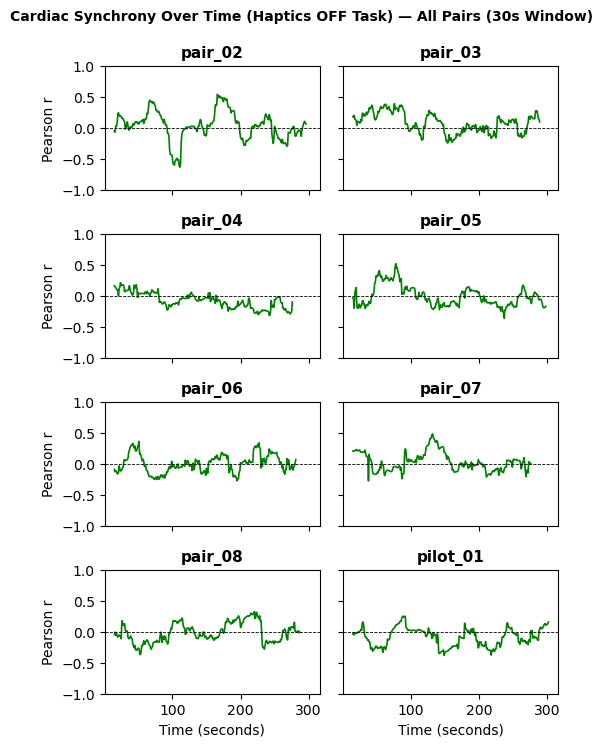

In [180]:
analysis_pairs = sorted(resampled_data["pair_id"].unique())
number_of_pairs = len(analysis_pairs)

# Create a 4 x 2 columns grid
main_figure, list_of_graphs = plt.subplots(
    nrows=4, ncols=2, figsize=(5.5, 7.5), sharex=True, sharey=True
)

# Flatten the 4x2 grid into a 1D list for easy looping
list_of_graphs = list_of_graphs.flatten()

# Loop through each pair
for current_index in range(number_of_pairs):
  current_pair_id = analysis_pairs[current_index]
  current_graph = list_of_graphs[current_index]

  time_seconds, heart_rate_alpha, heart_rate_bravo = get_session(
      current_pair_id, "hapticsOFF_task"
  )

  # First-differencing
  change_in_heart_rate_alpha = first_difference(heart_rate_alpha)
  change_in_heart_rate_bravo = first_difference(heart_rate_bravo)

  # Calculate windowed correlation 
  window_centres, window_correlations = windowed_correlation(
      change_in_heart_rate_alpha,
      change_in_heart_rate_bravo,
      window_size_seconds=30,
  )

  # Plot the synchrony curve
  current_graph.plot(
      window_centres, window_correlations, color="green", linewidth=1.2
  )

  # Zero reference line
  current_graph.axhline(0, color="black", linewidth=0.6, linestyle="--")

  # Subplot title and Y-axis limits
  current_graph.set_title(current_pair_id, fontsize=11, fontweight="bold")
  current_graph.set_ylim(-1, 1)

  # Add Y-axis label to the left-hand column 
  if current_index % 2 == 0:
    current_graph.set_ylabel("Pearson r")

  # Add X-axis label to the bottom two subplots 
  if current_index >= 6:
    current_graph.set_xlabel("Time (seconds)")

# Overall figure title
main_figure.suptitle(
    "Cardiac Synchrony Over Time (Haptics OFF Task) — All Pairs (30s Window)",
    fontsize=10,
    fontweight="bold",
    y=0.99,
)

plt.tight_layout()
plt.savefig("fig_synch_overtime_4x2.png", dpi=300, bbox_inches="tight")
plt.show()